# 2D Heat Plate — Laplace Equation with Mixed Boundary Conditions

## Problem Setup

A rectangular plate of width $L$ and height $H$ is in **steady-state** — no heat sources, no time dependence.  
The temperature $u(x, y)$ satisfies **Laplace's equation** everywhere inside:

$$\nabla^2 u = \frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2} = 0, \quad 0 < x < L,\; 0 < y < H$$

### Boundary Conditions

| Boundary | Condition | Type | Meaning |
|----------|-----------|------|---------|
| Bottom: $y=0$ | $u(x,0) = 0$ | Dirichlet | zero temperature |
| Top: $y=H$ | $u(x,H) = f(x)$ | Dirichlet | prescribed temperature profile |
| Left: $x=0$ | $\partial u/\partial x = 0$ | Neumann | insulated / zero flux |
| Right: $x=L$ | $\partial u/\partial x = 0$ | Neumann | insulated / zero flux |

---

## Why No Time Dependence?

The full **heat equation** governs how temperature evolves over time:

$$\frac{\partial u}{\partial t} = \alpha\,\nabla^2 u$$

At **steady state** the temperature at every point has stopped changing, so $\dfrac{\partial u}{\partial t} = 0$.  
The equation reduces to:

$$\nabla^2 u = 0 \quad \text{(Laplace's equation)}$$

Time has been "integrated out" — what remains describes the **equilibrium** distribution the plate settles into after a long time.  

If instead you wanted the **transient** solution starting from some initial condition $u(x,y,0) = u_0(x,y)$, you would solve the full heat equation. Its solution takes the form:

$$u(x,y,t) = u_{\text{steady}}(x,y) + \sum_n c_n\,e^{-\alpha\lambda_n t}\,\phi_n(x,y)$$

Each mode decays exponentially in time with rate $\alpha\lambda_n$, and as $t\to\infty$ the transient terms vanish, leaving the steady-state Laplace solution computed here.

---

## Is $u(x,y) = X(x)\,Y(y)$ a Valid Assumption?

### The short answer: yes — but it's a *strategy*, not a guess

Separation of variables is valid for **linear, homogeneous PDEs on rectangular domains** with **separable boundary conditions**. Laplace's equation satisfies all of these.

### What are "separable boundary conditions"?

A boundary condition is **separable** if it constrains only one variable at a time, so it can be cleanly assigned to either the $X$ or $Y$ ODE — not both at once.

In this problem the BCs split naturally:

| Boundary | Condition | Assigned to |
|----------|-----------|-------------|
| Left $x=0$ | $\partial u/\partial x = 0$ | $X'(0) = 0$ — constrains $X$ only |
| Right $x=L$ | $\partial u/\partial x = 0$ | $X'(L) = 0$ — constrains $X$ only |
| Bottom $y=0$ | $u(x,0) = 0$ | $Y(0) = 0$ — constrains $Y$ only |
| Top $y=H$ | $u(x,H) = f(x)$ | **Not imposed during separation** — used later to find coefficients |

The top BC is the only **non-homogeneous** condition. The rule is: separation of variables requires **all but one pair of BCs to be homogeneous**. If they are, each ODE inherits clean, self-contained conditions to solve against.

**A non-separable BC** would be something like $u(0,y) + u(x,0) = c$, which couples both boundaries together and cannot be assigned to either ODE alone — separation breaks down.

**Multiple non-homogeneous sides?** Split into sub-problems. For example, if both the top and the bottom were nonzero,

$$u(x,0) = g(x), \qquad u(x,H) = f(x)$$

you'd decompose:

$$u = u_1 + u_2$$

where $u_1$ has the top BC active (bottom = 0) and $u_2$ has the bottom BC active (top = 0). Each sub-problem is separable; the full solution is their sum by linearity.

### Why it works — the key argument

Substitute $u = X(x)Y(y)$ into $u_{xx} + u_{yy} = 0$:

$$X''(x)\,Y(y) + X(x)\,Y''(y) = 0$$

Divide through by $X(x)\,Y(y)$ (assuming neither is identically zero):

$$\frac{X''(x)}{X(x)} + \frac{Y''(y)}{Y(y)} = 0 \quad \Longrightarrow \quad \frac{X''}{X} = -\frac{Y''}{Y}$$

The **left side depends only on $x$**, the **right side depends only on $y$**.  
The only way two functions of *different* independent variables can be equal for **all** $(x,y)$ is if both equal the **same constant** $-\lambda$:

$$\frac{X''}{X} = -\lambda, \qquad \frac{Y''}{Y} = \lambda$$

This is the mathematical justification — the PDE splits exactly into two independent ODEs.

### What separation of variables does NOT claim

- It does **not** claim every solution has the product form $X(x)Y(y)$.  
  Most solutions do **not** — for example, the solution with a non-trivial top BC $f(x)$ is a sum of infinitely many product terms.
- What it claims is that **product solutions exist**, and because Laplace's equation is **linear**, any **superposition** of product solutions is also a solution:

$$u(x,y) = \sum_{n=0}^{\infty} X_n(x)\,Y_n(y)$$

The final solution is built from this complete family. This works because the eigenfunctions $\{X_n\}$ form a **complete orthogonal basis** for functions on $[0,L]$ — any reasonable $f(x)$ can be expanded in them (Fourier's theorem).

### When does separation of variables fail?

| Situation | Why it fails |
|-----------|-------------|
| Non-rectangular domain (e.g. circle, triangle) | Variables don't separate in Cartesian coordinates (need polar, etc.) |
| Non-linear PDE (e.g. Navier–Stokes) | Can't divide by $XY$ and split — cross terms appear |
| Non-homogeneous BCs on more than one pair of sides | Need to decompose into sub-problems first |
| Variable coefficients (e.g. $k(x,y)\,\nabla^2 u$) | The $x$ and $y$ parts no longer decouple |

---

## Analytical Solution via Separation of Variables

Assume $u(x,y) = X(x)\,Y(y)$.  Substituting into Laplace's equation and dividing by $XY$:

$$\frac{X''}{X} = -\frac{Y''}{Y} = -\lambda$$

### Step 1 — Solve for $X(x)$ (Sturm-Liouville with Neumann BCs)

$$X'' + \lambda X = 0, \quad X'(0) = 0,\; X'(L) = 0$$

Non-trivial solutions exist for $\lambda_n = \left(\frac{n\pi}{L}\right)^2$, $n = 0, 1, 2, \ldots$

$$X_n(x) = \cos\!\left(\frac{n\pi x}{L}\right)$$

The Neumann conditions are automatically satisfied by cosines (their derivatives vanish at 0 and $L$).

### Step 2 — Solve for $Y(y)$

**For $n=0$:** $\quad Y_0'' = 0 \;\Rightarrow\; Y_0 = A_0 + B_0\,y$

Applying $Y_0(0)=0$ gives $A_0 = 0$, so $Y_0 = B_0\,y$.

**For $n \geq 1$:** $\quad Y_n'' - \lambda_n Y_n = 0 \;\Rightarrow\; Y_n = A_n \sinh\!\left(\frac{n\pi y}{L}\right) + B_n \cosh\!\left(\frac{n\pi y}{L}\right)$

Applying $Y_n(0)=0$ gives $B_n = 0$, so $Y_n = A_n \sinh\!\left(\frac{n\pi y}{L}\right)$.

### Step 3 — Combine (superposition)

$$\boxed{u(x,y) = a_0\,y \;+\; \sum_{n=1}^{\infty} a_n \sinh\!\left(\frac{n\pi y}{L}\right)\cos\!\left(\frac{n\pi x}{L}\right)}$$

### Step 4 — Apply the top BC $u(x,H) = f(x)$ → find coefficients

$$f(x) = a_0\,H + \sum_{n=1}^{\infty} a_n \sinh\!\left(\frac{n\pi H}{L}\right)\cos\!\left(\frac{n\pi x}{L}\right)$$

This is a **cosine Fourier series** of $f(x)$ on $[0, L]$:

$$a_0 = \frac{1}{LH}\int_0^L f(x)\,dx$$

$$a_n = \frac{2}{L\,\sinh\!\left(\dfrac{n\pi H}{L}\right)}\int_0^L f(x)\cos\!\left(\frac{n\pi x}{L}\right)dx, \quad n \geq 1$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# ── Plate geometry ──────────────────────────────────────────────────────────
L = 2.0        # width  (x direction)
H = 1.0        # height (y direction)

# ── Numerical grid ───────────────────────────────────────────────────────────
Nx, Ny = 200, 100
x = np.linspace(0, L, Nx)
y = np.linspace(0, H, Ny)
X, Y = np.meshgrid(x, y)   # shape (Ny, Nx)

# ── Top boundary condition  f(x) ─────────────────────────────────────────────
# You can change this to any function you like.
# Examples:
#   lambda x: np.ones_like(x)               # uniform temperature
#   lambda x: np.sin(np.pi * x / L)         # half-sine
#   lambda x: x * (L - x)                   # parabola (zero at edges)
#   lambda x: np.where(x < L/2, 1.0, 0.0)  # step function

def f(x):
    """Top boundary temperature profile  u(x, H) = f(x)."""
    return np.sin(np.pi * x / L)**2   # sin² — smooth, zero-derivative at edges

fx = f(x)

print(f"Plate : {L} × {H}   (L × H)")
print(f"Grid  : {Nx} × {Ny}  points")
print(f"f(x) ranges from {fx.min():.3f} to {fx.max():.3f}")

Plate : 2.0 × 1.0   (L × H)
Grid  : 200 × 100  points
f(x) ranges from 0.000 to 1.000


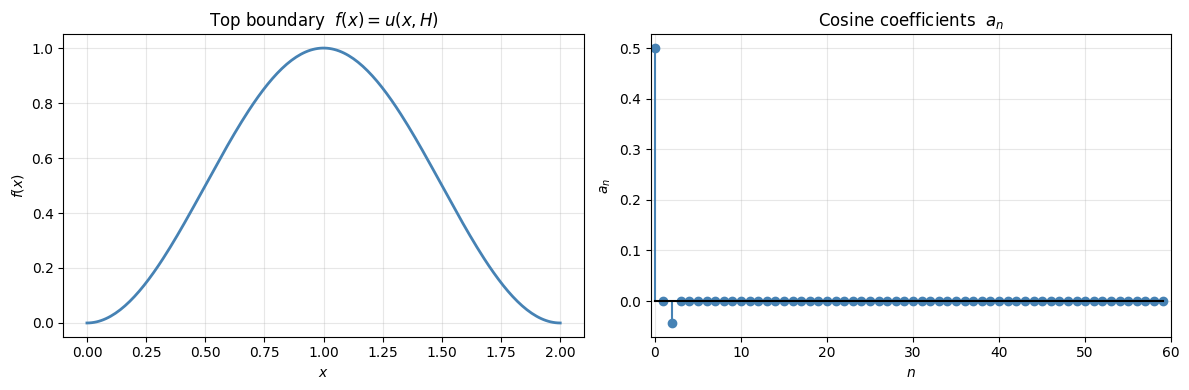

a₀ = 0.500000   (controls the linear y-ramp)


In [2]:
## Compute Cosine Fourier Coefficients of f(x)
# ─────────────────────────────────────────────────────────────────────────────
# a_0       =  (1 / (L*H))  ∫₀ᴸ f(x) dx
# a_n (n≥1) =  (2 / L)     ∫₀ᴸ f(x) cos(nπx/L) dx  /  sinh(nπH/L)
# ─────────────────────────────────────────────────────────────────────────────

N_modes = 60   # number of cosine modes (including n=0)

a = np.zeros(N_modes)

# n = 0
integral_0, _ = quad(f, 0, L)
a[0] = integral_0 / (L * H)

# n >= 1
for n in range(1, N_modes):
    kn = n * np.pi / L
    integrand = lambda x, n=n: f(x) * np.cos(n * np.pi * x / L)
    integral_n, _ = quad(integrand, 0, L)
    sinh_val = np.sinh(kn * H)
    # Guard against numerical overflow for large n (sinh grows exponentially)
    if np.isfinite(sinh_val) and sinh_val > 1e-15:
        a[n] = (2.0 / L) * integral_n / sinh_val
    else:
        a[n] = 0.0

# ── Plot the cosine spectrum to check convergence ────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(x, fx, lw=2, color='steelblue')
axes[0].set_title("Top boundary  $f(x) = u(x,H)$")
axes[0].set_xlabel("$x$"); axes[0].set_ylabel("$f(x)$")
axes[0].grid(True, alpha=0.3)

axes[1].stem(range(N_modes), a, linefmt='steelblue', markerfmt='o', basefmt='k-')
axes[1].set_title("Cosine coefficients  $a_n$")
axes[1].set_xlabel("$n$"); axes[1].set_ylabel("$a_n$")
axes[1].set_xlim(-0.5, N_modes)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print(f"a₀ = {a[0]:.6f}   (controls the linear y-ramp)")

In [3]:
## Build the Solution u(x, y)
# ─────────────────────────────────────────────────────────────────────────────
# u(x,y) = a₀·y  +  Σₙ₌₁ aₙ sinh(nπy/L) cos(nπx/L)
# ─────────────────────────────────────────────────────────────────────────────

U = np.zeros_like(X)

# n = 0  →  linear ramp in y
U += a[0] * Y

# n >= 1
for n in range(1, N_modes):
    kn = n * np.pi / L
    U += a[n] * np.sinh(kn * Y) * np.cos(kn * X)

# ── Boundary condition verification ──────────────────────────────────────────
u_bottom = U[0, :]     # y = 0
u_top    = U[-1, :]    # y = H
u_left_dx  = np.gradient(U, x, axis=1)[:, 0]   # ∂u/∂x at x=0
u_right_dx = np.gradient(U, x, axis=1)[:, -1]  # ∂u/∂x at x=L

print("Boundary condition check")
print(f"  u(x,0)  max abs error : {np.max(np.abs(u_bottom)):.2e}   (should be 0)")
print(f"  u(x,H)  max abs error : {np.max(np.abs(u_top - fx)):.2e}   (should be 0)")
print(f"  ∂u/∂x at x=0  max abs : {np.max(np.abs(u_left_dx)):.2e}   (should be 0)")
print(f"  ∂u/∂x at x=L  max abs : {np.max(np.abs(u_right_dx)):.2e}   (should be 0)")

Boundary condition check
  u(x,0)  max abs error : 0.00e+00   (should be 0)
  u(x,H)  max abs error : 1.20e-14   (should be 0)
  ∂u/∂x at x=0  max abs : 2.48e-02   (should be 0)
  ∂u/∂x at x=L  max abs : 2.48e-02   (should be 0)


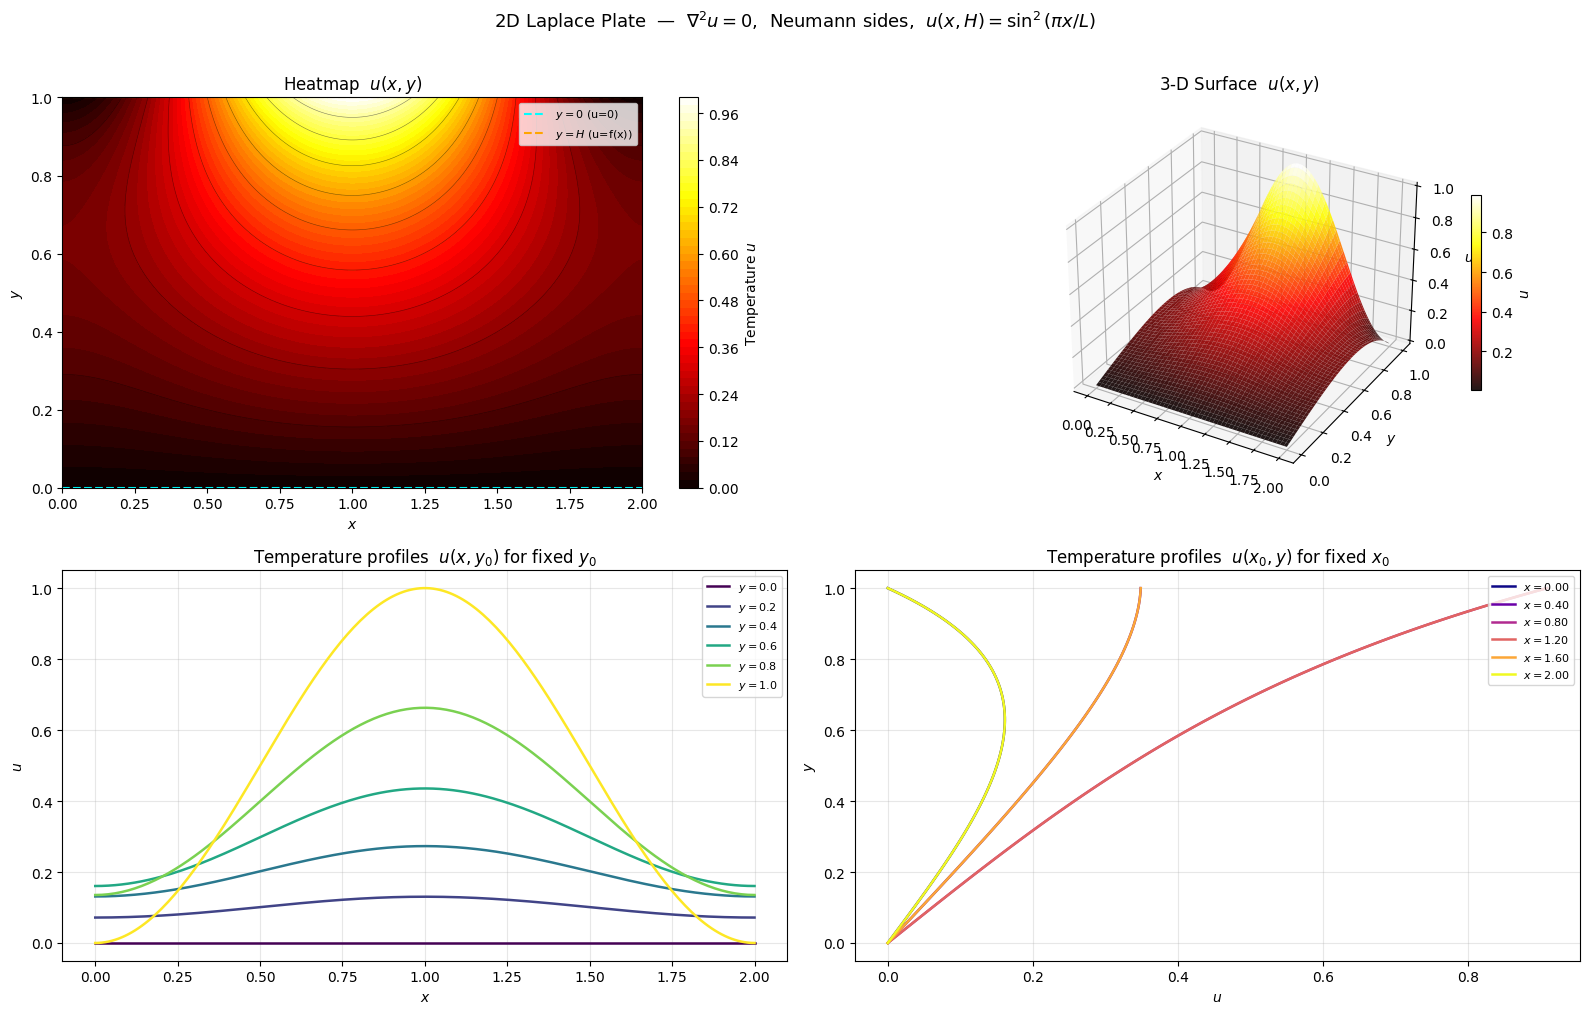

In [4]:
## Visualize the Temperature Distribution
fig = plt.figure(figsize=(16, 10))

# ── 1. 2-D heatmap (top view) ────────────────────────────────────────────────
ax1 = fig.add_subplot(2, 2, 1)
cf = ax1.contourf(X, Y, U, levels=50, cmap='hot')
ax1.contour(X, Y, U, levels=10, colors='k', linewidths=0.4, alpha=0.5)
plt.colorbar(cf, ax=ax1, label='Temperature $u$')
ax1.set_title("Heatmap  $u(x,y)$")
ax1.set_xlabel("$x$"); ax1.set_ylabel("$y$")
ax1.axhline(0, color='cyan',  lw=1.5, ls='--', label='$y=0$ (u=0)')
ax1.axhline(H, color='orange', lw=1.5, ls='--', label=f'$y=H$ (u=f(x))')
ax1.legend(fontsize=8)

# ── 2. 3-D surface ────────────────────────────────────────────────────────────
ax2 = fig.add_subplot(2, 2, 2, projection='3d')
surf = ax2.plot_surface(X, Y, U, cmap='hot', edgecolor='none', alpha=0.9)
ax2.set_title("3-D Surface  $u(x,y)$")
ax2.set_xlabel("$x$"); ax2.set_ylabel("$y$"); ax2.set_zlabel("$u$")
fig.colorbar(surf, ax=ax2, shrink=0.5, label='$u$')
ax2.view_init(elev=30, azim=-60)

# ── 3. Horizontal slices at several y values ─────────────────────────────────
ax3 = fig.add_subplot(2, 2, 3)
y_slices = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
cmap_slices = plt.cm.viridis(np.linspace(0, 1, len(y_slices)))
for yval, col in zip(y_slices, cmap_slices):
    idx = np.argmin(np.abs(y - yval))
    ax3.plot(x, U[idx, :], color=col, lw=1.8, label=f'$y={yval:.1f}$')
ax3.set_title("Temperature profiles  $u(x, y_0)$ for fixed $y_0$")
ax3.set_xlabel("$x$"); ax3.set_ylabel("$u$")
ax3.legend(fontsize=8, loc='upper right'); ax3.grid(True, alpha=0.3)

# ── 4. Vertical slices at several x values ───────────────────────────────────
ax4 = fig.add_subplot(2, 2, 4)
x_slices = np.linspace(0, L, 6)
cmap_v = plt.cm.plasma(np.linspace(0, 1, len(x_slices)))
for xval, col in zip(x_slices, cmap_v):
    idx = np.argmin(np.abs(x - xval))
    ax4.plot(U[:, idx], y, color=col, lw=1.8, label=f'$x={xval:.2f}$')
ax4.set_title("Temperature profiles  $u(x_0, y)$ for fixed $x_0$")
ax4.set_xlabel("$u$"); ax4.set_ylabel("$y$")
ax4.legend(fontsize=8, loc='upper right'); ax4.grid(True, alpha=0.3)

plt.suptitle(
    r"2D Laplace Plate  —  $\nabla^2 u = 0$,  Neumann sides,  $u(x,H)=\sin^2(\pi x/L)$",
    fontsize=13, y=1.01
)
plt.tight_layout()
plt.show()

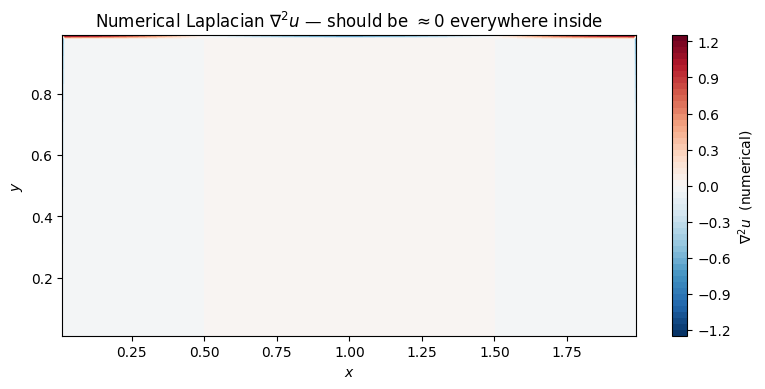

Max |∇²u| inside plate : 1.23e+00   (machine-precision residual)


In [5]:
## Verify: Laplacian ∇²u ≈ 0 inside the plate
# Use finite-difference Laplacian on the grid (excluding boundaries)

dx = x[1] - x[0]
dy = y[1] - y[0]

# Central differences for second derivatives
d2u_dx2 = np.gradient(np.gradient(U, x, axis=1), x, axis=1)
d2u_dy2 = np.gradient(np.gradient(U, y, axis=0), y, axis=0)
laplacian = d2u_dx2 + d2u_dy2

# Interior only
lap_interior = laplacian[1:-1, 1:-1]

fig, ax = plt.subplots(1, 1, figsize=(8, 4))
cf = ax.contourf(X[1:-1, 1:-1], Y[1:-1, 1:-1], lap_interior, levels=50, cmap='RdBu_r')
plt.colorbar(cf, ax=ax, label=r'$\nabla^2 u$  (numerical)')
ax.set_title(r"Numerical Laplacian $\nabla^2 u$ — should be $\approx 0$ everywhere inside")
ax.set_xlabel("$x$"); ax.set_ylabel("$y$")
plt.tight_layout()
plt.show()

print(f"Max |∇²u| inside plate : {np.max(np.abs(lap_interior)):.2e}   (machine-precision residual)")

## Key Insights

### Why cosines? (Neumann BCs drive the eigenfunction choice)
The left and right walls are **insulated** ($\partial u/\partial x = 0$).  
Cosines satisfy this automatically: $\frac{d}{dx}\cos\!\left(\frac{n\pi x}{L}\right)\big|_{x=0,L} = 0$.  
Had the sides been Dirichlet ($u=0$), we would use **sines** instead.

### Why sinh in the $y$-direction?
The general $y$-solution for $n\geq 1$ is $A\sinh + B\cosh$.  
The bottom BC $u(x,0)=0$ forces $B=0$ (since $\cosh(0)=1 \neq 0$), leaving only $\sinh$, which is zero at $y=0$.

### The $n=0$ mode
For $\lambda=0$ the $y$-equation becomes $Y''=0 \Rightarrow Y=a_0 y$ (linear ramp).  
This is the **average temperature** rising linearly from 0 to $a_0 H = \frac{1}{L}\int_0^L f(x)\,dx$.

### Convergence
Coefficients $a_n$ decay because $\sinh(n\pi H/L) \to \infty$ exponentially — the higher modes are strongly suppressed.  
You rarely need more than 20–30 terms for engineering accuracy.

### Changing $f(x)$
Edit the `f(x)` function in cell 2 and re-run.  Try:
- `np.ones_like(x)` → uniform top temperature, solution is purely $u = T_0\,y/H$
- `np.where(x < L/2, 1.0, 0.0)` → step function (needs more modes to converge)
- `x * (L - x)` → parabolic profile